# Detecção de EPIs em obras: YOLOv8 versus YOLO11

**Objetivo:** treinar duas versões do YOLO para detectar equipamentos de proteção
individual (EPIs), pessoas e as demais classes da base Construction-PPE.
Comparar as métricas no conjunto de teste e apresentar imagens com as previsões
de bounding boxes, classes e confiança.

**Como reproduzir:** selecione uma GPU em **Ambiente de execução > Alterar tipo de
ambiente de execução** e clique em **Executar tudo**. Ao terminar, salve este
notebook com as novas saídas. O formato de entrega escolhido é o link do
repositório público no GitHub, com o código e os resultados disponíveis.

Este notebook baixa a base e os pesos pré-treinados oficiais. Usa a API Python
da Ultralytics indicada no enunciado e faz fine-tuning dos dois modelos.
Quando os arquivos de uma execução já realizada estão presentes no projeto,
o gerador inclui seus resultados no início deste notebook para consulta.
As células de código seguintes permitem reproduzir o experimento completo.


## Resultados da execução salva

Execução realizada no Google Colab em 30/10/2026, com Tesla T4 e 30 épocas por modelo. As tabelas e imagens desta seção foram importadas dos arquivos reais de `entrega.zip`, enviado após a execução. Não é necessário treinar novamente para consultar estes resultados. Os logs de execução das células não estão neste arquivo.

| Modelo | Precisão | Recall | mAP50 | mAP50-95 | Inferência |
|---|---:|---:|---:|---:|---:|
| YOLOv8n | 62.19% | 51.42% | 54.46% | 27.66% | 16.05 ms |
| YOLO11n | 54.58% | 51.57% | 54.25% | 27.41% | 14.41 ms |

Avaliação em 141 imagens de teste. Inferência medida pelo validador, batch 1 e FP32, sem pré e pós-processamento.


### Conclusão da execução

Foram treinados YOLOv8n e YOLO11n por 30 épocas cada, com imagens de
640 pixels, batch 16 e seed 42, a partir de pesos pré-treinados em COCO.
Após a auditoria, foram usadas 1132 imagens de treino,
143 de validação e 141 de teste.
Os checkpoints foram selecionados na validação, antes da avaliação no teste.

O YOLOv8n obteve mAP50 de 0.5446 e mAP50-95 de 0.2766.
O YOLO11n obteve mAP50 de 0.5425 e mAP50-95 de 0.2741.
YOLOv8n obteve o maior mAP50-95, com vantagem de 0.25 pontos percentuais.

Na GPU Tesla T4, a etapa de inferência medida pelo validador levou
16.05 ms/imagem para YOLOv8n e 14.41
ms/imagem para YOLO11n, com batch 1 e FP32, sem pré/pós-processamento.
Esses tempos são indicativos desta execução, sem repetições de benchmark.

As imagens com boxes permitem confrontar as previsões com as anotações de referência.
O AP por classe mostra diferenças que a média geral pode esconder.
Foi feita uma execução por versão; não foram estimadas variância ou significância
estatística. O experimento se limita à base Construction-PPE e às suas anotações.


### Métricas e tempo de inferência no teste

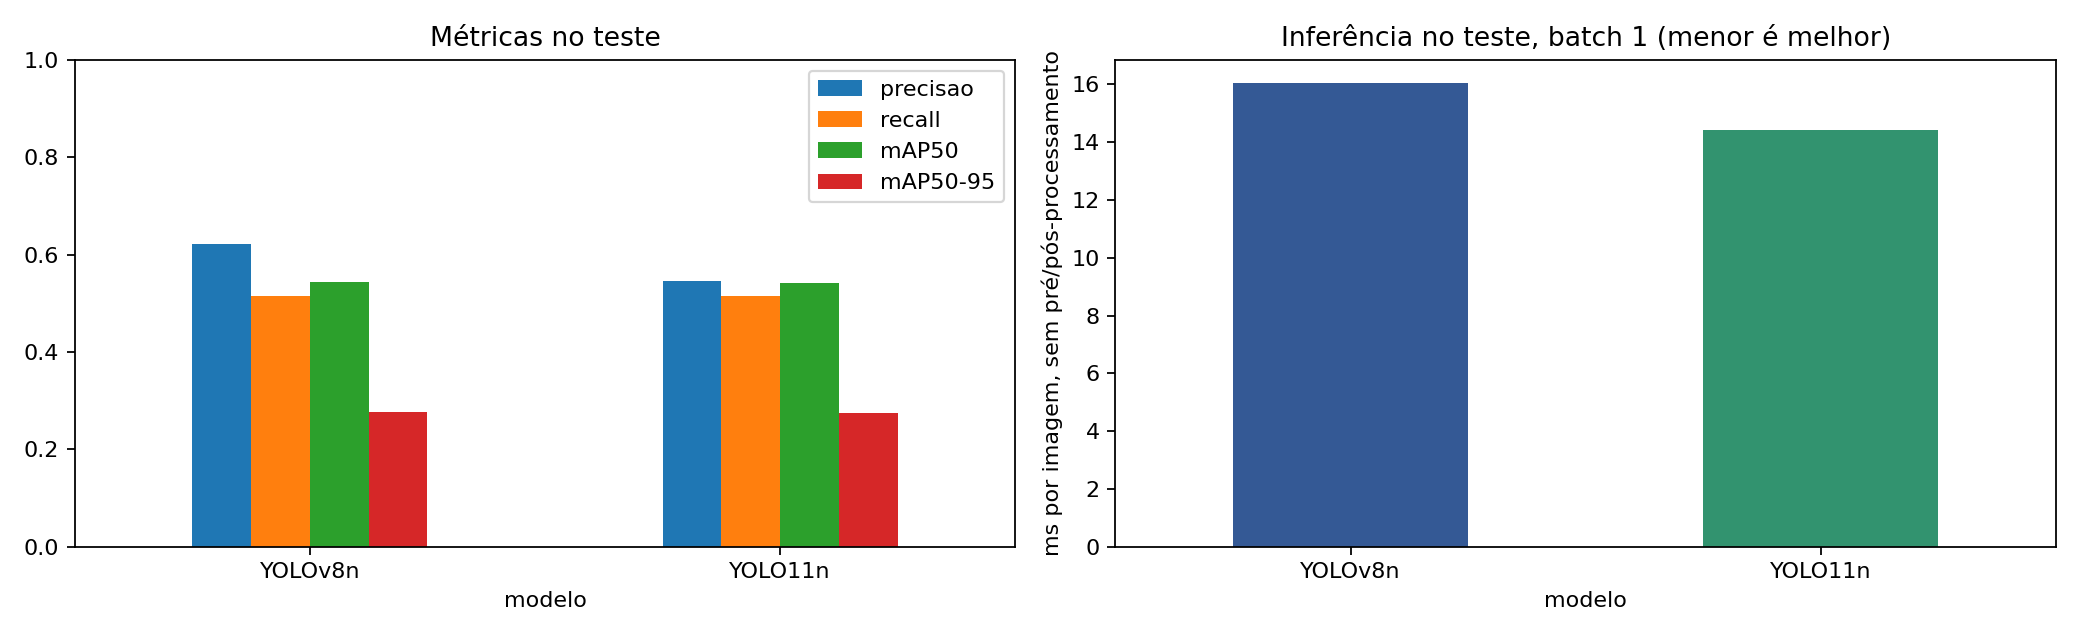


### AP50-95 por classe

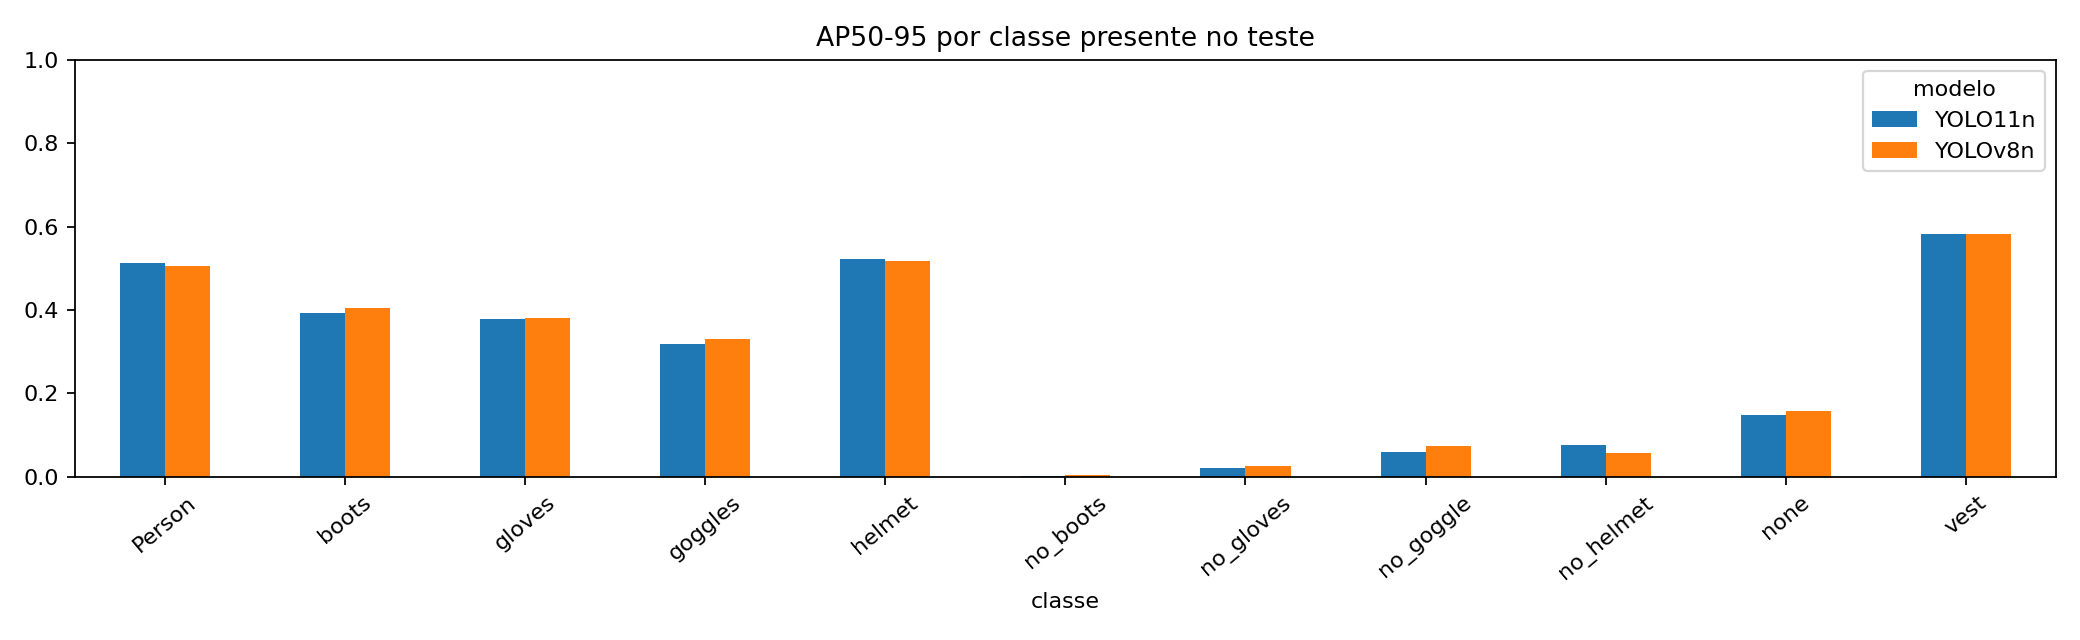


### Boxes no teste: exemplo 1. Referência, YOLOv8n e YOLO11n.

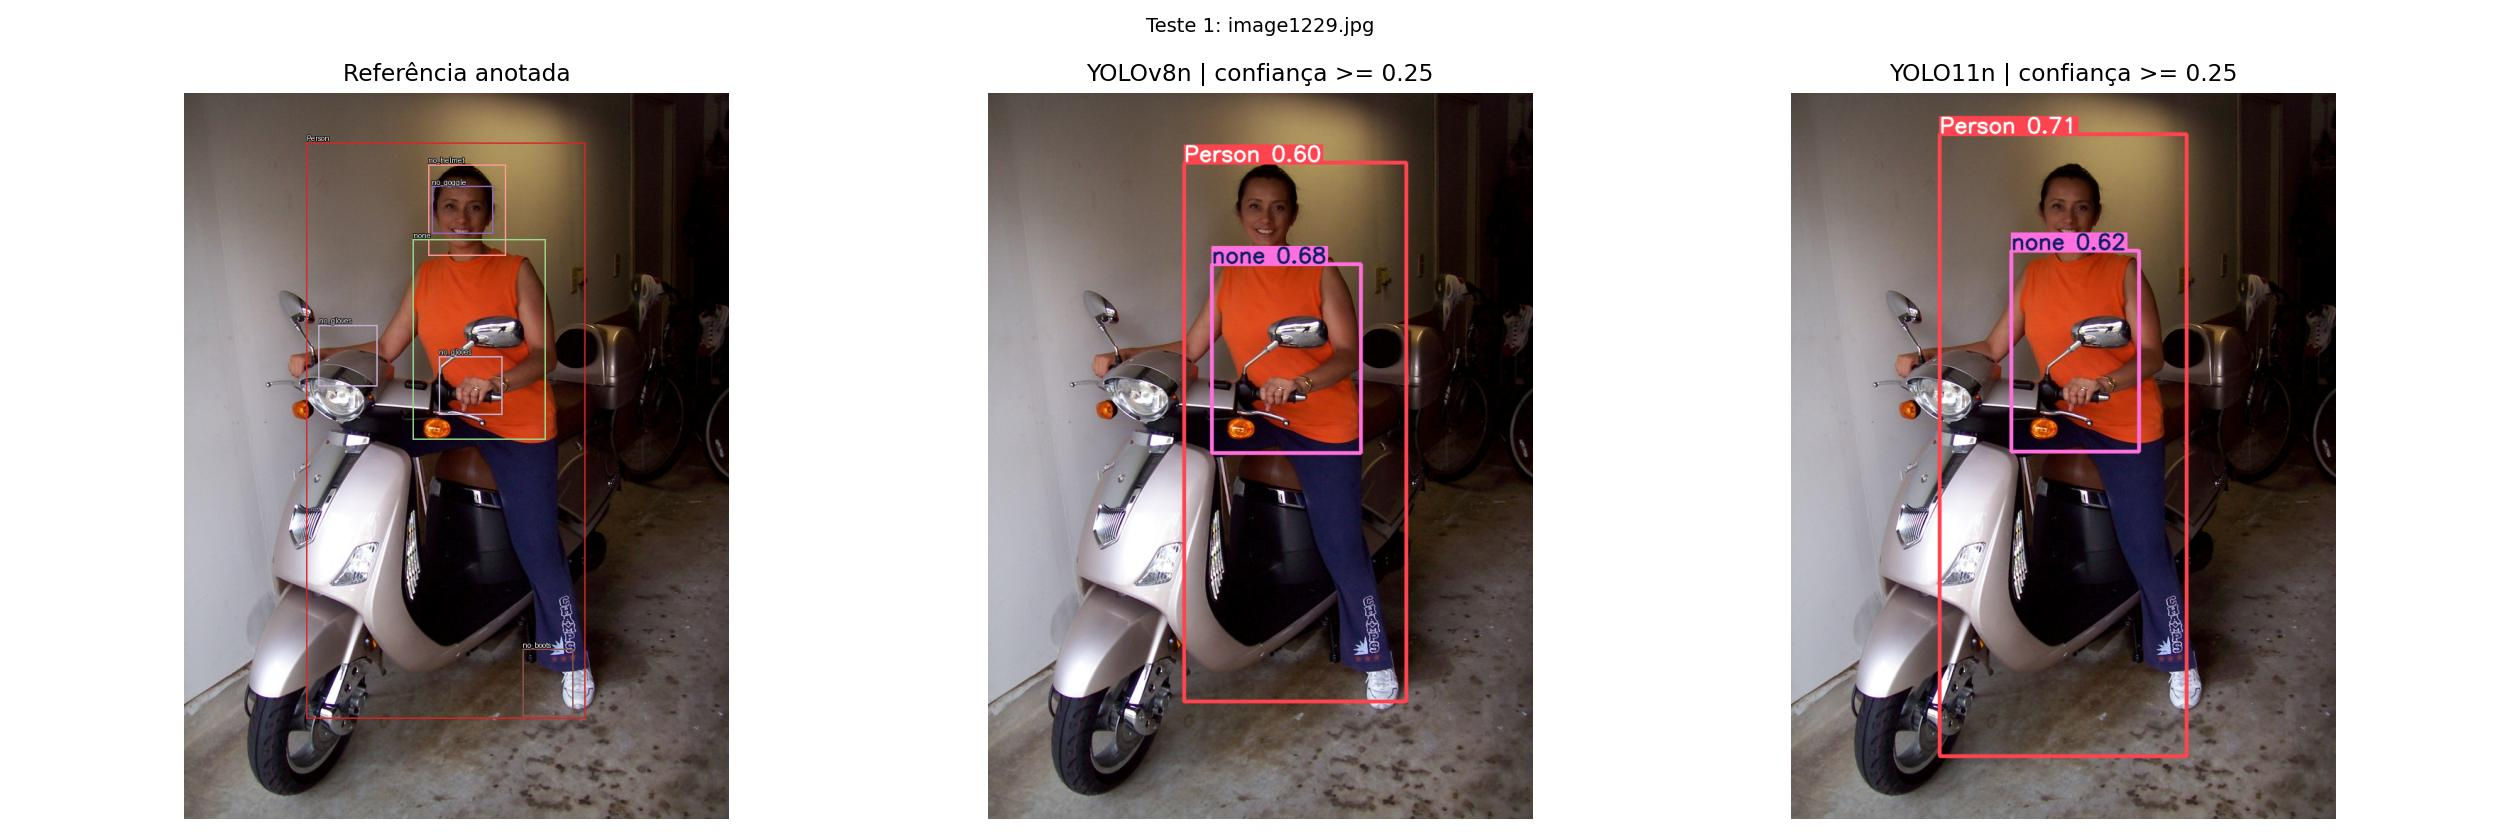


### Boxes no teste: exemplo 2. Referência, YOLOv8n e YOLO11n.

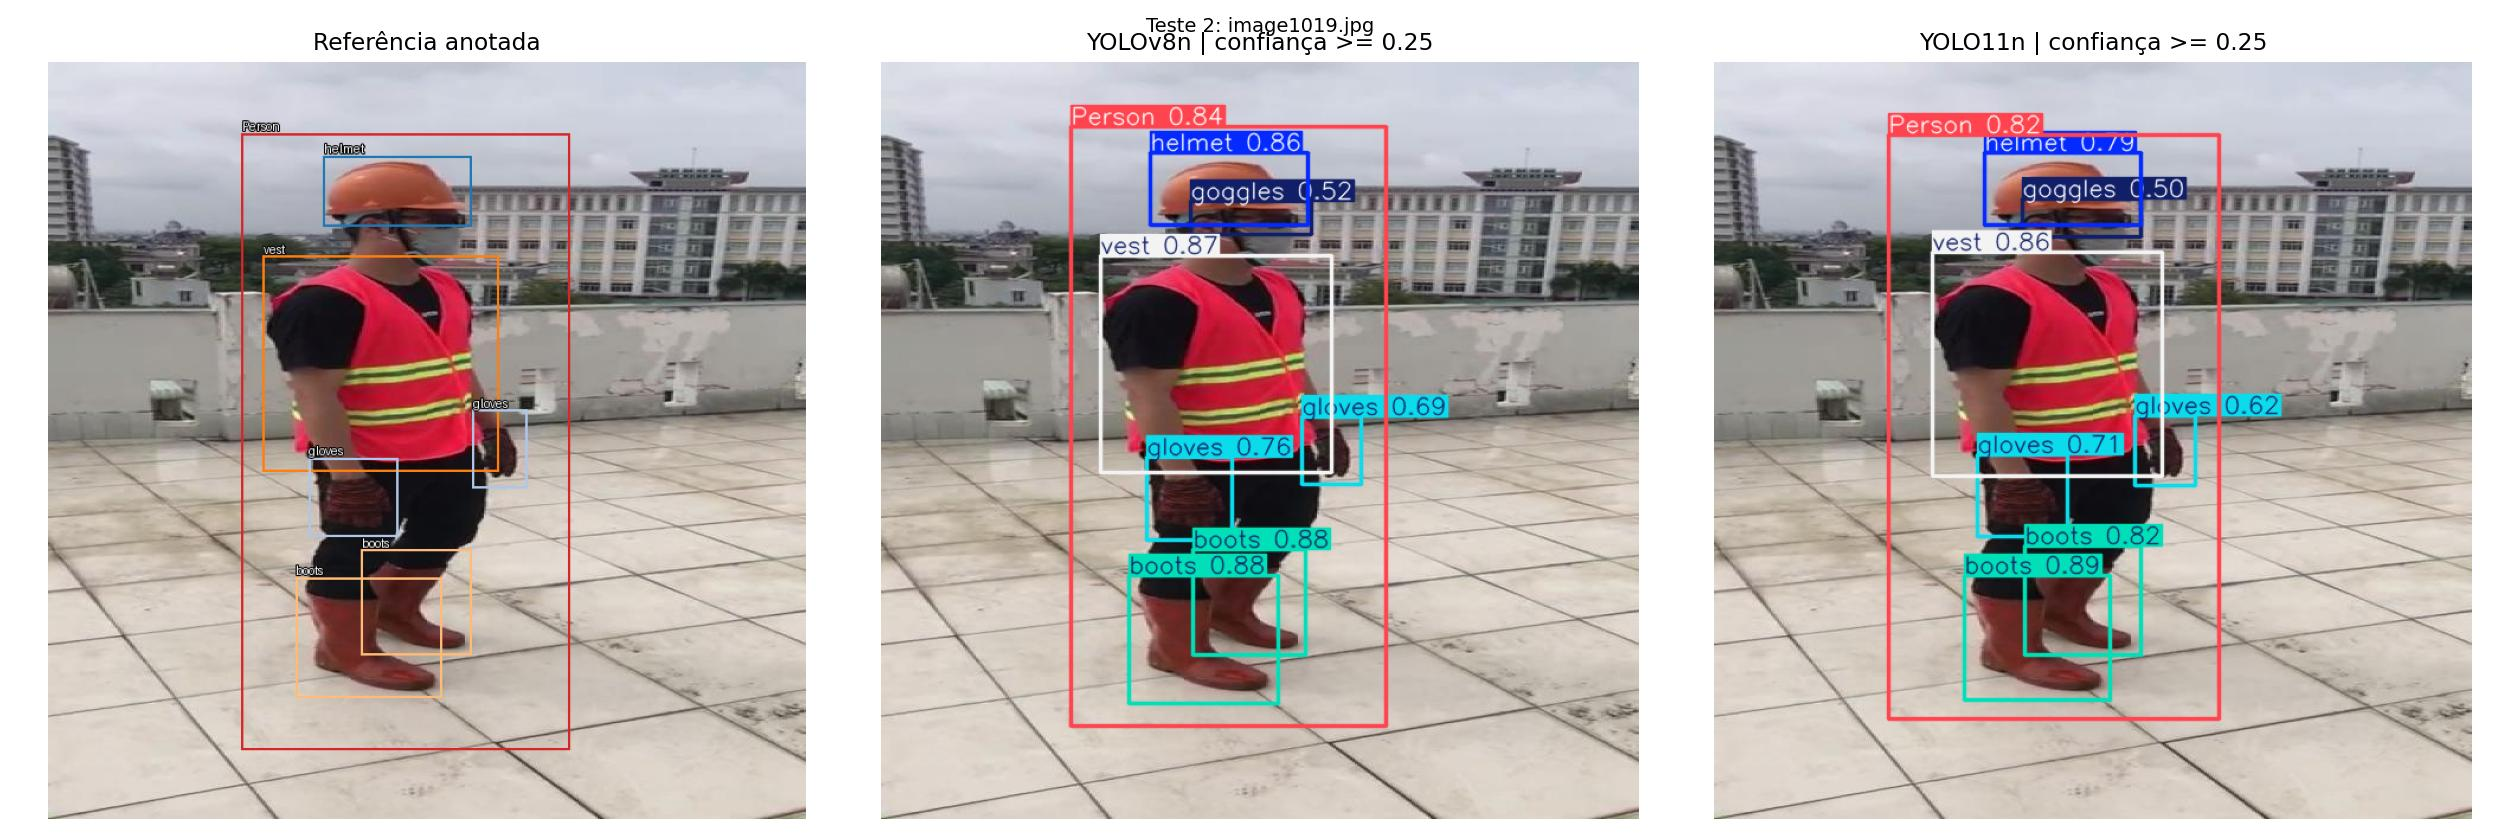


### Boxes no teste: exemplo 3. Referência, YOLOv8n e YOLO11n.

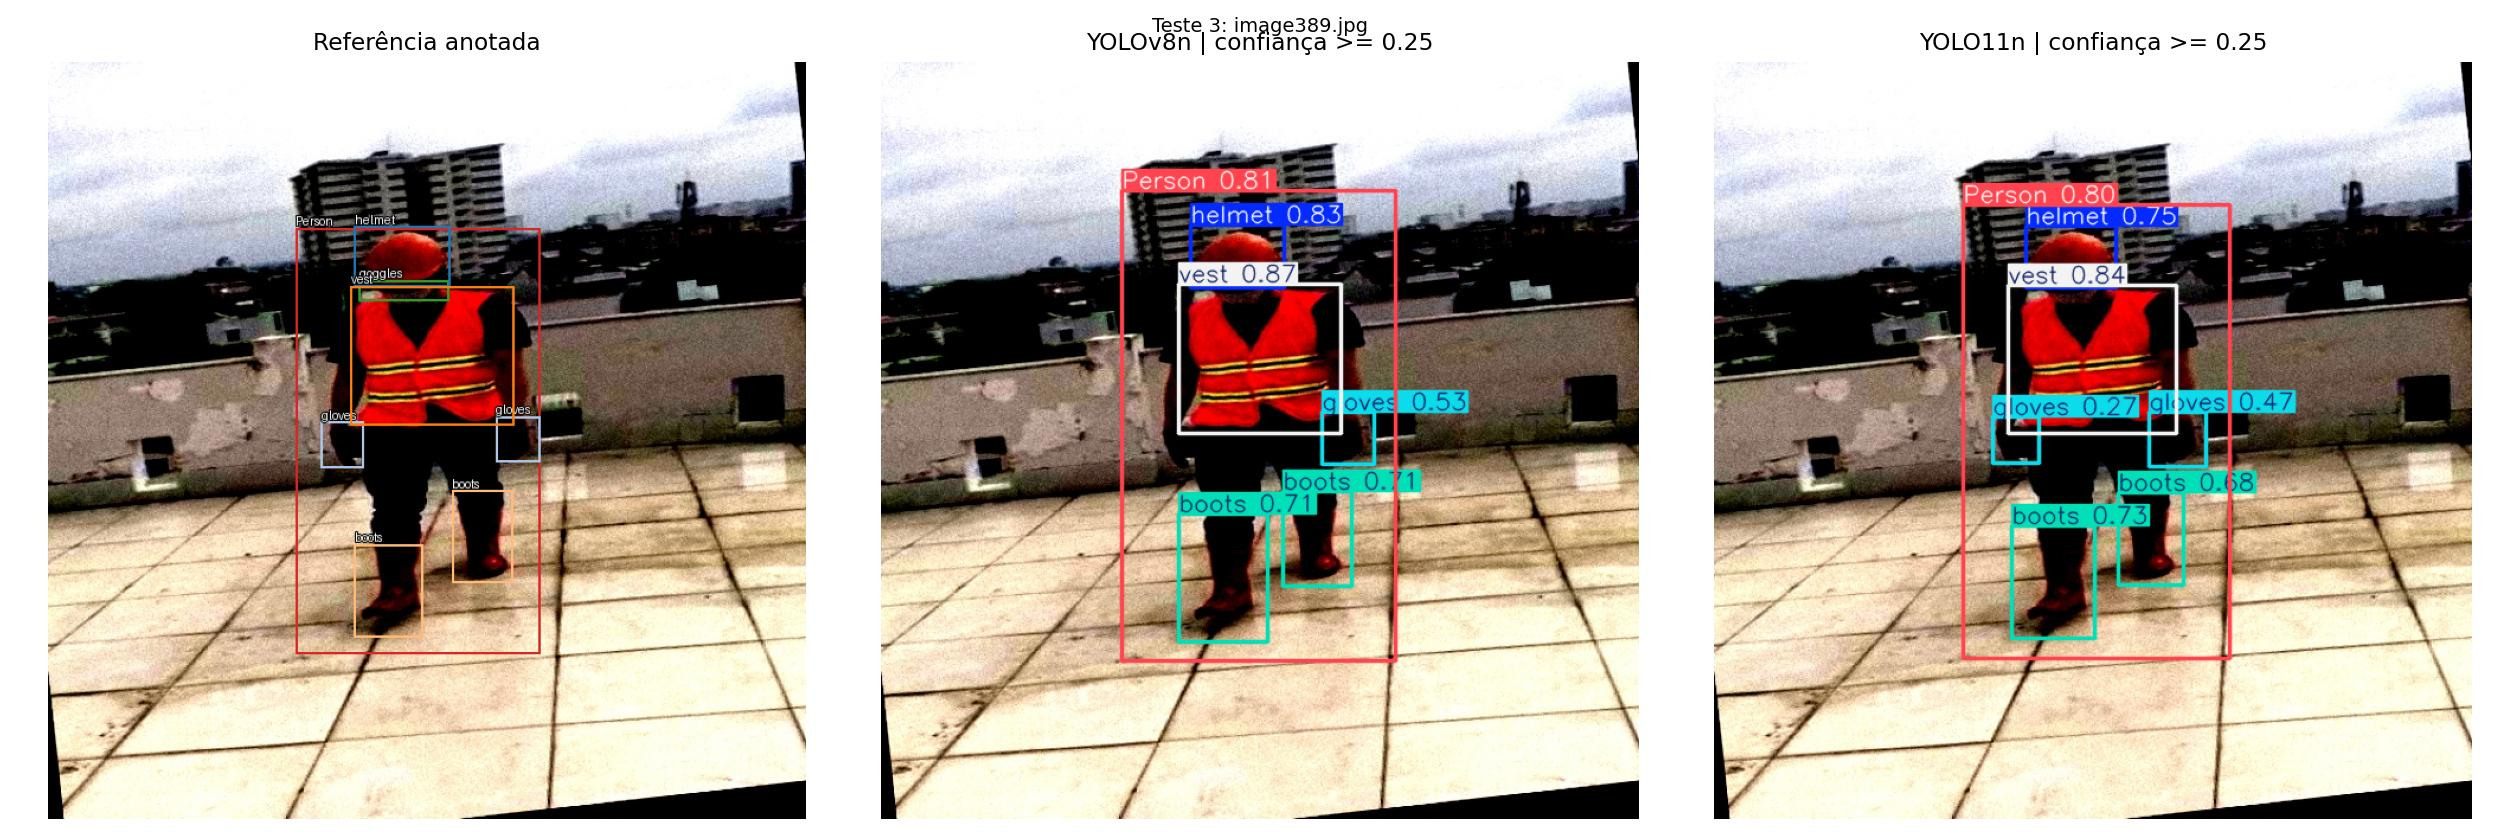


### Boxes no teste: exemplo 4. Referência, YOLOv8n e YOLO11n.

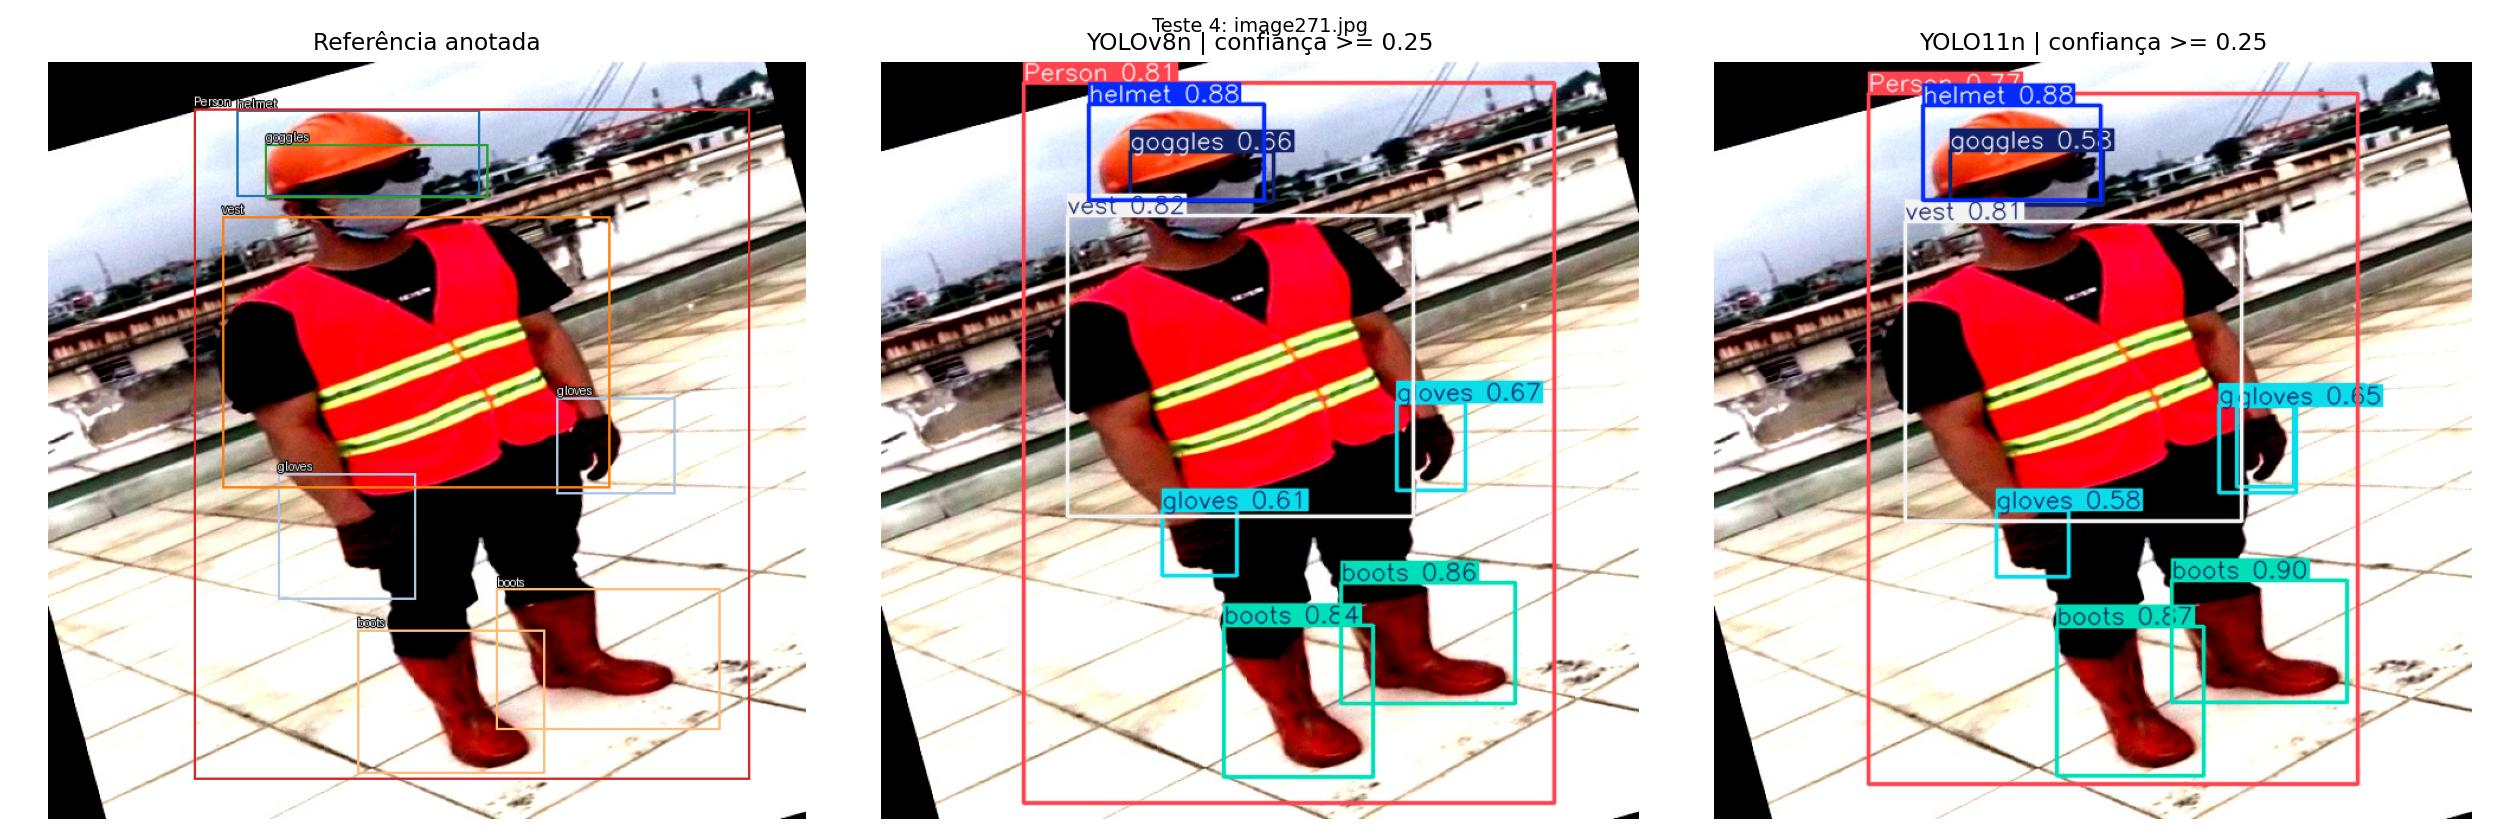


### Boxes no teste: exemplo 5. Referência, YOLOv8n e YOLO11n.

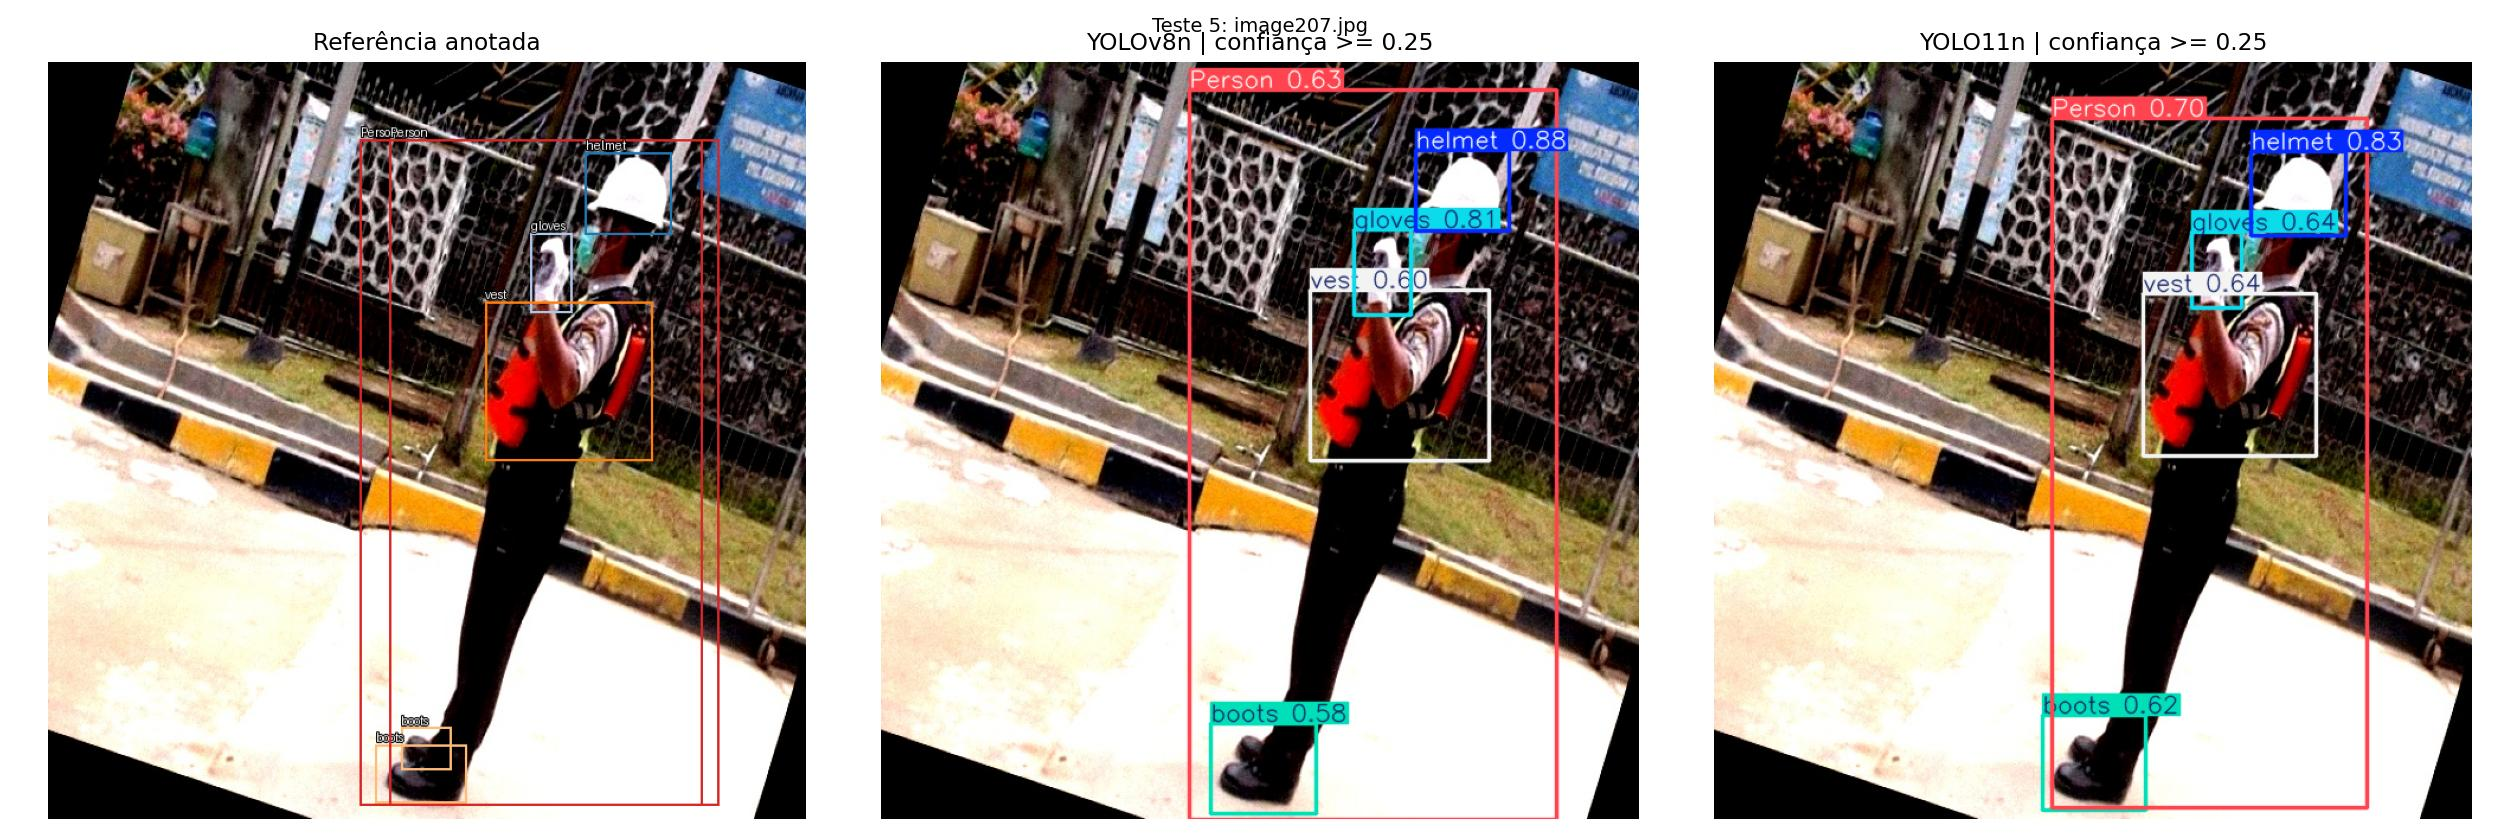


### Boxes no teste: exemplo 6. Referência, YOLOv8n e YOLO11n.

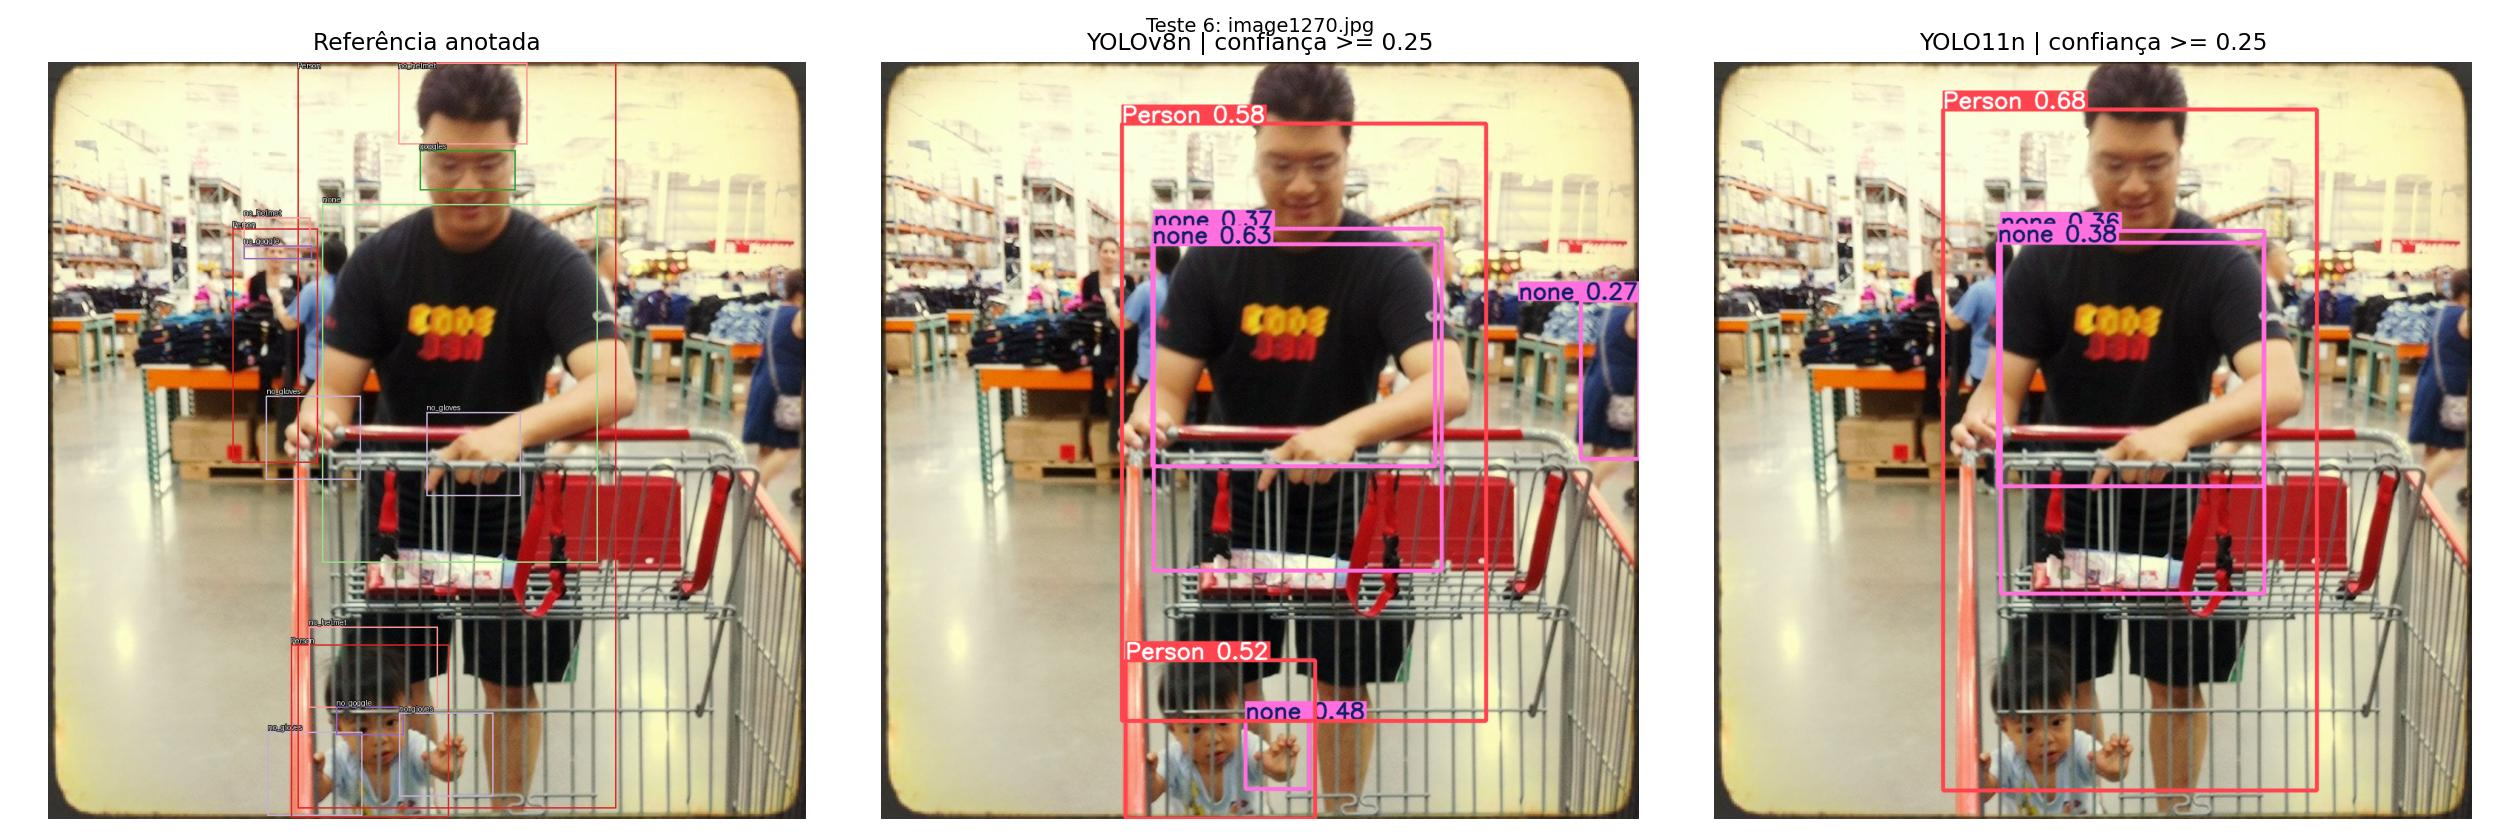


## Parâmetros editáveis

Edite somente o bloco abaixo para escolher o tamanho dos modelos, as épocas,
a resolução, o batch, a parada antecipada e a taxa de aprendizado. Os dois modelos usam os mesmos
ajustes. As tabelas, os nomes das pastas e a conclusão acompanham o tamanho escolhido.

Depois de alterar os parâmetros, execute o notebook desde o início para treinar
os dois modelos com a nova configuração. Cada execução cria uma pasta e um ZIP
próprios. Os resultados publicados da execução original são preservados.

`EPOCHS` é o limite máximo por modelo. `PATIENCE = 10` ativa a parada após
10 épocas sem melhora do mAP50-95 na validação, critério da versão usada da
Ultralytics. O checkpoint `best.pt` é preservado e usado na avaliação final.
`PATIENCE = 0` desativa essa parada. A conclusão registra as épocas efetivamente
realizadas, que podem ser diferentes entre os dois modelos.


In [ ]:
# ALTERE ESTES VALORES ANTES DE EXECUTAR TUDO.
TAMANHO = 'n'  # 'n': nano, 's': small, 'm': medium
EPOCHS = 30
PATIENCE = 0  # épocas sem melhora na validação; 0 desativa a parada antecipada
IMGSZ = 640  # múltiplo de 32, por exemplo: 640, 768 ou 960
BATCH = 16  # se faltar memória, reduza para 8 ou 4 nos dois modelos
SEED = 42
LR0 = 0.001  # taxa inicial de aprendizado do AdamW
CONF_VISUAL = 0.25  # altera as boxes exibidas; não o cálculo do mAP

from math import isfinite

if TAMANHO not in ('n', 's', 'm'):
    raise ValueError("TAMANHO deve ser 'n', 's' ou 'm'.")
for nome, valor in [('EPOCHS', EPOCHS), ('IMGSZ', IMGSZ), ('BATCH', BATCH)]:
    if type(valor) is not int or valor <= 0:
        raise ValueError(f'{nome} deve ser um inteiro positivo.')
if IMGSZ % 32:
    raise ValueError('IMGSZ deve ser múltiplo de 32.')
if type(SEED) is not int or SEED < 0:
    raise ValueError('SEED deve ser um inteiro não negativo.')
if type(PATIENCE) is not int or PATIENCE < 0:
    raise ValueError('PATIENCE deve ser um inteiro não negativo.')
if not isinstance(LR0, (int, float)) or not isfinite(LR0) or LR0 <= 0:
    raise ValueError('LR0 deve ser um número positivo e finito.')
if not isinstance(CONF_VISUAL, (int, float)) or not isfinite(CONF_VISUAL) or not 0 <= CONF_VISUAL <= 1:
    raise ValueError('CONF_VISUAL deve estar entre 0 e 1.')

NOME_V8 = f'YOLOv8{TAMANHO}'
NOME_V11 = f'YOLO11{TAMANHO}'
MODELOS = {NOME_V8: f'yolov8{TAMANHO}.pt', NOME_V11: f'yolo11{TAMANHO}.pt'}
print('Modelos:', MODELOS)
print(f'Limite de épocas: {EPOCHS} | paciência: {PATIENCE} | resolução: {IMGSZ} | batch: {BATCH} | seed: {SEED}')


## 1. Problema, base e protocolo

Detecção de objetos responde **o que aparece e onde aparece**. Cada previsão
contém a classe, uma caixa e um valor de confiança.

A [Construction-PPE](https://docs.ultralytics.com/datasets/detect/construction-ppe/)
possui, conforme a documentação, 1.416 imagens: 1.132 de treino, 143 de validação
e 141 de teste. Contém 11 classes: `helmet`, `gloves`, `vest`, `boots`, `goggles`,
`none`, `Person`, `no_helmet`, `no_goggle`, `no_gloves` e `no_boots`.
As classes e seus nomes originais são preservados, inclusive a classe genérica `none`.
Há classes explícitas para ausência de alguns EPIs; ausência de uma detecção
de equipamento, isoladamente, não comprova que ele esteja ausente.

**Protocolo:**

- YOLOv8 e YOLO11 iniciam com pesos oficiais pré-treinados em COCO.
- Mesmos dados, épocas, resolução, batch e seed definidos no bloco de parâmetros.
- Mesmo otimizador AdamW, hiperparâmetros explícitos e regra de parada `PATIENCE`.
- O treino aprende os pesos. A validação escolhe o checkpoint `best.pt`.
- O teste fica reservado para avaliar os checkpoints já escolhidos.
- Uma execução por modelo. Usar a mesma variante (`n`, `s` ou `m`) aproxima o porte,
  mas não torna suas arquiteturas ou quantidades de parâmetros idênticas.

Antes do treino, o notebook verifica as anotações e elimina duplicatas exatas
por conteúdo na ordem treino, validação e teste, preservando os arquivos originais.
Os totais efetivamente usados e as exclusões serão exibidos abaixo.


## 2. Instalação

A versão da Ultralytics está fixada para manter a mesma API nas duas execuções.
O PyTorch fornecido pelo Colab é preservado. A lista completa de versões será exportada.


In [ ]:
import subprocess
import sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *['ultralytics==8.3.221', 'pandas>=2.2,<3', 'matplotlib>=3.8,<4', 'PyYAML>=6,<7']])


## 3. Configuração e ambiente

O bloco de parâmetros no início controla esta execução. Os valores usados,
os pesos de origem e o ambiente são registrados automaticamente.


In [ ]:
import os
import json
import random
import time
import platform
import shutil
from datetime import datetime, timezone
from pathlib import Path

BASE = (Path.cwd() / 'trabalho').resolve()
BASE.mkdir(parents=True, exist_ok=True)
os.environ['YOLO_CONFIG_DIR'] = str(BASE / 'config')
os.environ['WANDB_MODE'] = 'disabled'

import torch
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import ultralytics
from PIL import Image, ImageDraw
from IPython.display import display, Markdown, FileLink
from ultralytics import YOLO, settings

if not torch.cuda.is_available():
    raise RuntimeError('GPU indisponível. No Colab, selecione GPU em Ambiente de execução > Alterar tipo de ambiente de execução e execute novamente.')
DEVICE = 0
PASTA = BASE / 'execucoes' / datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
PASTA.mkdir(parents=True)
settings.update({'datasets_dir': str(BASE / 'dados'), 'sync': False, 'wandb': False})

PARAMETROS = dict(epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED,
                 optimizer='AdamW', lr0=LR0, lrf=0.01, weight_decay=0.0005,
                 patience=PATIENCE, deterministic=True, device=DEVICE, workers=2,
                 amp=True, cache=False, close_mosaic=min(5, EPOCHS), plots=True, save=True,
                 save_period=10, fraction=1.0)
AMBIENTE = {'python': sys.version, 'plataforma': platform.platform(),
            'ultralytics': ultralytics.__version__, 'torch': torch.__version__,
            'cuda': torch.version.cuda, 'gpu': torch.cuda.get_device_name(0),
            'inicio_utc': datetime.now(timezone.utc).isoformat()}
(PASTA / 'configuracao.json').write_text(json.dumps(
    {'modelos': MODELOS, 'treino': PARAMETROS, 'ambiente': AMBIENTE,
     'confianca_visual': CONF_VISUAL}, indent=2, ensure_ascii=False), encoding='utf-8')
(PASTA / 'dependencias.txt').write_text(
    subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True), encoding='utf-8')
print(json.dumps(AMBIENTE, indent=2, ensure_ascii=False))
print('Saída:', PASTA)
CHECKPOINTS, TEMPOS, EPOCAS_REALIZADAS = {}, {}, {}


## 4. Download e auditoria

A configuração oficial faz o download automático da base. A auditoria usa
SHA-256 dos arquivos para evitar que uma cópia exata seja usada em divisões
diferentes. Isso não detecta imagens parecidas, recortes ou recompressões.


In [ ]:
"""Auditoria das anotações e remoção de duplicatas exatas entre divisões."""

import hashlib
import math
from pathlib import Path


def ler_boxes(arquivo, numero_classes):
    """Lê classe, centro x/y e largura/altura normalizados no formato YOLO."""
    boxes = []
    for numero, linha in enumerate(Path(arquivo).read_text(encoding='utf-8').splitlines(), 1):
        if not linha.strip():
            continue
        try:
            valores = [float(item) for item in linha.split()]
            if len(valores) != 5 or not all(math.isfinite(v) for v in valores):
                raise ValueError('esperados cinco números finitos')
            classe, x, y, largura, altura = valores
            if not classe.is_integer() or not 0 <= classe < numero_classes:
                raise ValueError('classe inválida')
            if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < largura <= 1 and 0 < altura <= 1):
                raise ValueError('coordenadas inválidas')
            boxes.append((int(classe), x, y, largura, altura))
        except ValueError as erro:
            raise ValueError(f'{arquivo}, linha {numero}: {erro}') from erro
    return boxes


def arquivo_label(imagem):
    partes = list(Path(imagem).parts)
    indice = len(partes) - 1 - partes[::-1].index('images')
    partes[indice] = 'labels'
    return Path(*partes).with_suffix('.txt')


def preparar_divisoes(divisoes, numero_classes):
    """Mantém a primeira ocorrência de cada arquivo na ordem train, val, test.

    Não altera os originais. SHA-256 compara bytes, não imagens visualmente parecidas.
    As listas retornadas são usadas por ambos os modelos.
    """
    vistos, listas, resumo, duplicatas, contagens = {}, {}, {}, [], {}
    extensoes = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
    for split in ['train', 'val', 'test']:
        imagens = sorted(p for p in Path(divisoes[split]).rglob('*') if p.suffix.lower() in extensoes)
        listas[split], contagens[split] = [], [0] * numero_classes
        for imagem in imagens:
            digest = hashlib.sha256(imagem.read_bytes()).hexdigest()
            if digest in vistos:
                duplicatas.append({'excluida': str(imagem), 'mantida': vistos[digest], 'sha256': digest})
                continue
            boxes = ler_boxes(arquivo_label(imagem), numero_classes)
            vistos[digest] = str(imagem)
            listas[split].append(imagem.resolve())
            for classe, *_ in boxes:
                contagens[split][classe] += 1
        usados = len(listas[split])
        if not usados:
            raise ValueError(f'O conjunto {split} ficou vazio após a auditoria.')
        resumo[split] = {'imagens_originais': len(imagens), 'imagens_usadas': usados,
                        'duplicatas_excluidas': len(imagens) - usados,
                        'boxes': sum(contagens[split])}
    return listas, resumo, duplicatas, contagens


def resumir_classes(modelo, nomes, contagens, indices, precisao, recall, ap50, ap):
    """Zero para classe anotada sem detecções; omite classe ausente no teste."""
    posicoes = {int(classe): i for i, classe in enumerate(indices)}
    linhas = []
    for classe in sorted(nomes):
        if not contagens[classe]:
            continue
        i = posicoes.get(classe)
        p = float(precisao[i]) if i is not None else 0.0
        r = float(recall[i]) if i is not None else 0.0
        linhas.append({'modelo': modelo, 'classe': nomes[classe],
                       'boxes_teste': contagens[classe],
                       'precisao': p,
                       'recall': r,
                       'f1': 2 * p * r / (p + r) if p + r else 0.0,
                       'AP50': float(ap50[i]) if i is not None else 0.0,
                       'AP50-95': float(ap[i]) if i is not None else 0.0})
    return linhas


In [ ]:
from ultralytics.data.utils import check_det_dataset

dados = check_det_dataset('construction-ppe.yaml')
NOMES = {int(k): v for k, v in dados['names'].items()}
LISTAS, RESUMO, DUPLICATAS, CONTAGENS = preparar_divisoes(
    {s: dados[s] for s in ['train', 'val', 'test']}, len(NOMES))

# Novos manifestos apontam para os arquivos originais, sem movê-los.
config_base = {'path': str(Path(dados['path']).resolve()), 'names': NOMES}
for split, imagens in LISTAS.items():
    manifesto = PASTA / f'{split}.txt'
    manifesto.write_text(''.join(str(p) + '\n' for p in imagens), encoding='utf-8')
    config_base[split] = str(manifesto)
DATA_YAML = PASTA / 'base.yaml'
DATA_YAML.write_text(yaml.safe_dump(config_base, sort_keys=False), encoding='utf-8')
auditoria = {'resumo': RESUMO, 'duplicatas': DUPLICATAS, 'boxes_por_classe': CONTAGENS}
(PASTA / 'auditoria.json').write_text(json.dumps(auditoria, indent=2, ensure_ascii=False), encoding='utf-8')

# Seleção das imagens visuais feita antes de conhecer os resultados.
AMOSTRAS = random.Random(SEED).sample(LISTAS['test'], min(6, len(LISTAS['test'])))
(PASTA / 'amostras.json').write_text(json.dumps([p.name for p in AMOSTRAS], indent=2), encoding='utf-8')
display(pd.DataFrame(RESUMO).T)
distribuicao = pd.DataFrame(CONTAGENS, index=[NOMES[i] for i in range(len(NOMES))])
distribuicao.index.name = 'classe'
distribuicao.to_csv(PASTA / 'distribuicao.csv')
display(distribuicao)
ax = distribuicao.plot.bar(figsize=(12, 4), title='Quantidade de boxes por classe e divisão')
ax.set_ylabel('Boxes anotadas')
plt.tight_layout()
plt.savefig(PASTA / 'distribuicao.png', dpi=140)
plt.show()
print('Duplicatas excluídas:', len(DUPLICATAS))


## 5. Exemplos das anotações

Estas caixas são as anotações de referência, usadas no aprendizado.
As previsões dos modelos serão mostradas depois, em imagens de teste.


In [ ]:
def imagem_anotada(caminho):
    imagem = Image.open(caminho).convert('RGB')
    desenho = ImageDraw.Draw(imagem)
    w, h = imagem.size
    for classe, x, y, largura, altura in ler_boxes(arquivo_label(caminho), len(NOMES)):
        canto = ((x - largura / 2) * w, (y - altura / 2) * h,
                 (x + largura / 2) * w, (y + altura / 2) * h)
        cor = tuple(int(c * 255) for c in plt.get_cmap('tab20')(classe)[:3])
        desenho.rectangle(canto, outline=cor, width=max(2, w // 350))
        desenho.text((max(0, canto[0]), max(0, canto[1] - 12)), NOMES[classe], fill='white', stroke_width=1, stroke_fill='black')
    return imagem

exemplos = random.Random(SEED).sample(LISTAS['train'], min(3, len(LISTAS['train'])))
fig, eixos = plt.subplots(1, len(exemplos), figsize=(16, 5), squeeze=False)
for eixo, caminho in zip(eixos[0], exemplos):
    eixo.imshow(imagem_anotada(caminho))
    eixo.set_title(caminho.name[:45])
    eixo.axis('off')
plt.tight_layout()
plt.savefig(PASTA / 'anotacoes_treino.jpg', dpi=130)
plt.show()


## 6. Treinamento do YOLOv8

O modelo recebe as imagens e as caixas de referência da base. A cada época,
a biblioteca registra perdas e métricas de validação. `best.pt` é escolhido
automaticamente pela função de fitness de validação da Ultralytics.


In [ ]:
inicio = time.perf_counter()
modelo = YOLO(MODELOS[NOME_V8])
modelo.train(data=str(DATA_YAML), project=str(PASTA / 'treinos'), name=NOME_V8.lower(), **PARAMETROS)
CHECKPOINTS[NOME_V8] = Path(modelo.trainer.best)
EPOCAS_REALIZADAS[NOME_V8] = len(pd.read_csv(modelo.trainer.csv))
TEMPOS[NOME_V8] = (time.perf_counter() - inicio) / 60
del modelo
torch.cuda.empty_cache()
print('Checkpoint:', CHECKPOINTS[NOME_V8])


## 7. Treinamento do YOLO11

Usa os mesmos manifestos e parâmetros. O histórico de cada modelo fica em
uma pasta própria para evitar que os resultados sejam sobrescritos.


In [ ]:
inicio = time.perf_counter()
modelo = YOLO(MODELOS[NOME_V11])
modelo.train(data=str(DATA_YAML), project=str(PASTA / 'treinos'), name=NOME_V11.lower(), **PARAMETROS)
CHECKPOINTS[NOME_V11] = Path(modelo.trainer.best)
EPOCAS_REALIZADAS[NOME_V11] = len(pd.read_csv(modelo.trainer.csv))
TEMPOS[NOME_V11] = (time.perf_counter() - inicio) / 60
del modelo
torch.cuda.empty_cache()
print('Checkpoint:', CHECKPOINTS[NOME_V11])


## 8. Avaliação no teste e comparação quantitativa

- **Precisão:** proporção das detecções consideradas positivas que estão corretas.
- **Recall:** proporção dos objetos anotados que foram encontrados.
- **F1 por classe:** média harmônica da precisão e do recall daquela classe.
- **Macro-F1:** média dos F1 das classes presentes no teste, com o mesmo peso por classe.
- **IoU:** interseção dividida pela união entre caixa prevista e caixa de referência.
- **mAP50:** média da precisão média por classe, exigindo IoU de pelo menos 0,50.
- **mAP50-95:** média em limiares de IoU de 0,50 até 0,95; exige localização mais precisa.

As métricas vão de 0 a 1. Quanto maior, melhor. Precisão e recall são os resumos
calculados pela Ultralytics no ponto de máximo F1 de suas curvas; não são
necessariamente os valores do limiar de 0,25 usado nas imagens demonstrativas.
O mAP considera a curva de confiança, usando `conf=0.001` para avaliação.

A velocidade abaixo é o tempo da etapa de inferência por imagem informado pelo
validador, com batch 1, mesma GPU e precisão FP32. Exclui pré e pós-processamento
e é uma medição aproximada desta execução. O tempo de treino inclui carregamento,
validação e operações de saída, além da otimização dos pesos.


In [ ]:
linhas, por_classe = [], []
for nome, checkpoint in CHECKPOINTS.items():
    if not checkpoint.is_file():
        raise FileNotFoundError(f'Checkpoint ausente: {checkpoint}')
    modelo = YOLO(str(checkpoint))
    metricas = modelo.val(data=str(DATA_YAML), split='test', imgsz=IMGSZ,
                          batch=1, device=DEVICE, half=False, conf=0.001, iou=0.7,
                          plots=True, save_txt=True, save_conf=True,
                          project=str(PASTA / 'teste'), name=nome.lower(), workers=2)
    # Os arrays seguem ap_class_index, não todas as classes da base.
    classes_modelo = resumir_classes(nome, NOMES, CONTAGENS['test'],
                                    metricas.box.ap_class_index, metricas.box.p,
                                    metricas.box.r, metricas.box.ap50, metricas.box.ap)
    por_classe.extend(classes_modelo)
    macro_f1 = sum(c['f1'] for c in classes_modelo) / len(classes_modelo)
    linhas.append({'modelo': nome, 'precisao': float(metricas.box.mp),
                   'recall': float(metricas.box.mr), 'mAP50': float(metricas.box.map50),
                   'mAP50-95': float(metricas.box.map),
                   'macro_f1': macro_f1,
                   'inferencia_ms': float(metricas.speed['inference']),
                   'tempo_treino_min': TEMPOS[nome],
                   'epocas_realizadas': EPOCAS_REALIZADAS[nome],
                   'parametros_milhoes': sum(p.numel() for p in modelo.model.parameters()) / 1e6,
                   'pesos_MB': checkpoint.stat().st_size / 1e6})
    del modelo
    torch.cuda.empty_cache()

comparacao = pd.DataFrame(linhas)
classes = pd.DataFrame(por_classe)
comparacao.to_csv(PASTA / 'comparacao.csv', index=False)
classes.to_csv(PASTA / 'comparacao_por_classe.csv', index=False)
display(comparacao.round(4))
display(classes.round(4))
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
comparacao.set_index('modelo')[['precisao', 'recall', 'macro_f1', 'mAP50', 'mAP50-95']].plot.bar(ax=eixos[0], ylim=(0, 1), rot=0)
eixos[0].set_title('Métricas no teste')
comparacao.set_index('modelo')['inferencia_ms'].plot.bar(ax=eixos[1], rot=0, color=['#345995', '#32936f'])
eixos[1].set_title('Inferência no teste, batch 1 (menor é melhor)')
eixos[1].set_ylabel('ms por imagem, sem pré/pós-processamento')
plt.tight_layout()
plt.savefig(PASTA / 'comparacao.png', dpi=160)
plt.show()
classes.pivot(index='classe', columns='modelo', values='AP50-95').plot.bar(figsize=(13, 4), ylim=(0, 1), rot=40)
plt.title('AP50-95 por classe presente no teste')
plt.tight_layout()
plt.savefig(PASTA / 'comparacao_por_classe.png', dpi=160)
plt.show()
classes.pivot(index='classe', columns='modelo', values='f1').plot.bar(figsize=(13, 4), ylim=(0, 1), rot=40)
plt.title('F1 por classe presente no teste')
plt.tight_layout()
plt.savefig(PASTA / 'f1_por_classe.png', dpi=160)
plt.show()


## 9. Curvas de treinamento e matrizes de confusão

As perdas e métricas por época ajudam a examinar o aprendizado. As matrizes
do **teste** mostram confusões entre classes, objetos perdidos e detecções extras.
Os gráficos completos também serão exportados no ZIP.


In [ ]:
for nome, checkpoint in CHECKPOINTS.items():
    display(Markdown(f'### {nome}'))
    arquivos = [checkpoint.parent.parent / 'results.png',
                PASTA / 'teste' / nome.lower() / 'confusion_matrix_normalized.png',
                PASTA / 'teste' / nome.lower() / 'BoxPR_curve.png']
    for arquivo in arquivos:
        if arquivo.exists():
            imagem = Image.open(arquivo).convert('RGB')
            imagem.thumbnail((1200, 900))
            display(imagem)


## 10. Resultados visuais com bounding boxes

Os modelos fazem previsões em **todas** as imagens de teste, salvas com boxes,
classes e confiança. Abaixo, seis imagens escolhidas por seed antes dos treinos
mostram, lado a lado, a anotação de referência e a previsão de cada versão.
Ambos usam confiança mínima de 0,25 e o mesmo limiar de NMS (IoU 0,70).
Esse limiar de NMS é diferente dos limiares de IoU usados no cálculo do AP.

Compare caixas que faltam, caixas extras e classes confundidas. O número de
boxes desenhadas pode mudar ao alterar a confiança, sem alterar os pesos treinados.


In [ ]:
PASTA_VISUAL = PASTA / 'visuais'
PASTA_VISUAL.mkdir()
PREVISOES = {}
selecionadas = {str(p) for p in AMOSTRAS}
for nome, checkpoint in CHECKPOINTS.items():
    modelo = YOLO(str(checkpoint))
    PREVISOES[nome] = {}
    resultados = modelo.predict(source=str(PASTA / 'test.txt'),
                                stream=True, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                                conf=CONF_VISUAL, iou=0.7, half=False,
                                save=True, save_txt=True, save_conf=True,
                                project=str(PASTA / 'previsoes'), name=nome.lower(), verbose=False)
    for resultado in resultados:
        if str(Path(resultado.path).resolve()) in selecionadas:
            PREVISOES[nome][Path(resultado.path).name] = resultado.plot()[:, :, ::-1].copy()
    del modelo
    torch.cuda.empty_cache()

for indice, caminho in enumerate(AMOSTRAS, 1):
    fig, eixos = plt.subplots(1, 3, figsize=(18, 6))
    eixos[0].imshow(imagem_anotada(caminho))
    eixos[0].set_title('Referência anotada')
    for eixo, nome in zip(eixos[1:], MODELOS):
        eixo.imshow(PREVISOES[nome][caminho.name])
        eixo.set_title(f'{nome} | confiança >= {CONF_VISUAL}')
    for eixo in eixos:
        eixo.axis('off')
    fig.suptitle(f'Teste {indice}: {caminho.name}', fontsize=10)
    plt.tight_layout()
    plt.savefig(PASTA_VISUAL / f'comparacao_{indice:02d}.jpg', dpi=140)
    plt.show()


## 11. Conclusão e limites do experimento

A conclusão abaixo usa somente os números desta execução. A diferença de mAP
é expressa em pontos percentuais. Uma execução não estabelece superioridade
geral: o resultado depende da base, da seed, do orçamento de treino e do hardware.

Uma classe ausente no teste não tem sua qualidade avaliada. Mesmo após remover
duplicatas exatas, imagens muito parecidas ou da mesma cena podem permanecer
em divisões diferentes. Não foi realizado agrupamento por obra ou por câmera.


In [ ]:
v8 = comparacao.set_index('modelo').loc[NOME_V8]
v11 = comparacao.set_index('modelo').loc[NOME_V11]
diferenca = float(v11['mAP50-95'] - v8['mAP50-95'])
if abs(diferenca) < 0.00005:
    resultado_principal = 'Os modelos tiveram mAP50-95 praticamente igual na precisão apresentada.'
else:
    melhor = NOME_V11 if diferenca > 0 else NOME_V8
    resultado_principal = f'{melhor} obteve o maior mAP50-95, com vantagem de {abs(diferenca) * 100:.2f} pontos percentuais.'
texto = f"""# Conclusão da execução

Foram treinados {NOME_V8} e {NOME_V11} com limite de {EPOCHS} épocas por modelo,
com imagens de
{IMGSZ} pixels, batch {BATCH} e seed {SEED}, a partir de pesos pré-treinados em COCO.
Foram realizadas {int(v8['epocas_realizadas'])} épocas para {NOME_V8} e
{int(v11['epocas_realizadas'])} épocas para {NOME_V11}. O parâmetro PATIENCE foi {PATIENCE}.
Após a auditoria, foram usadas {len(LISTAS['train'])} imagens de treino,
{len(LISTAS['val'])} de validação e {len(LISTAS['test'])} de teste.
Os checkpoints foram selecionados na validação, antes da avaliação no teste.

O {NOME_V8} obteve mAP50 de {v8['mAP50']:.4f} e mAP50-95 de {v8['mAP50-95']:.4f}.
O {NOME_V11} obteve mAP50 de {v11['mAP50']:.4f} e mAP50-95 de {v11['mAP50-95']:.4f}.
{resultado_principal}

O macro-F1 foi {v8['macro_f1']:.4f} para {NOME_V8} e {v11['macro_f1']:.4f}
para {NOME_V11}, calculado pela média dos F1 por classe, com o mesmo peso
para cada classe presente no teste. As tabelas exportadas incluem o F1 de cada classe.

Na GPU {AMBIENTE['gpu']}, a etapa de inferência medida pelo validador levou
{v8['inferencia_ms']:.2f} ms/imagem para {NOME_V8} e {v11['inferencia_ms']:.2f}
ms/imagem para {NOME_V11}, com batch 1 e FP32, sem pré/pós-processamento.
Esses tempos são indicativos desta execução, sem repetições de benchmark.

As imagens com boxes permitem confrontar as previsões com as anotações de referência.
O AP por classe mostra diferenças que a média geral pode esconder.
Foi feita uma execução por versão; não foram estimadas variância ou significância
estatística. O experimento se limita à base Construction-PPE e às suas anotações.
"""
ausentes = [NOMES[i] for i, n in enumerate(CONTAGENS['test']) if n == 0]
if ausentes:
    texto += '\nClasses sem boxes no teste, sem avaliação específica: ' + ', '.join(ausentes) + '.\n'
(PASTA / 'conclusao.md').write_text(texto, encoding='utf-8')
display(Markdown(texto))


## 12. Exportação e entrega

O ZIP inclui pesos treinados, tabelas CSV, gráficos, matrizes, boxes de todas as
imagens de teste, exemplos lado a lado, auditoria da base, configuração e conclusão.
Não inclui as imagens originais completas da base.

**Entrega ao professor:** envie o link do repositório público no GitHub.
O repositório reúne o notebook, as métricas, os históricos de treinamento e as
imagens com boxes. O README relaciona cada pedido do professor às evidências.
Guarde o ZIP como cópia dos resultados. O Colab é usado para executar ou
reproduzir o experimento; a entrega escolhida é o repositório.


In [ ]:
nome_zip = f'entrega_{TAMANHO}_ate{EPOCHS}ep_{PASTA.name}'
ARQUIVO_ZIP = Path(shutil.make_archive(str(PASTA.parent / nome_zip), 'zip', root_dir=PASTA))
print(f'Arquivo de resultados: {ARQUIVO_ZIP} ({ARQUIVO_ZIP.stat().st_size / 1e6:.1f} MB)')
try:
    from google.colab import files
except ImportError:
    display(FileLink(str(ARQUIVO_ZIP)))
else:
    files.download(str(ARQUIVO_ZIP))


## Referências

1. [Guia Ultralytics indicado no enunciado](https://docs.ultralytics.com/pt/quickstart/).
2. [Construction-PPE: base, autores, classes e licença AGPL-3.0](https://docs.ultralytics.com/datasets/detect/construction-ppe/).
3. [YOLOv8](https://docs.ultralytics.com/models/yolov8/) e [YOLO11](https://docs.ultralytics.com/models/yolo11/).
4. [Treinamento](https://docs.ultralytics.com/modes/train/), [validação](https://docs.ultralytics.com/modes/val/) e [predição](https://docs.ultralytics.com/modes/predict/).
5. [Configuração da base na versão usada](https://github.com/ultralytics/ultralytics/blob/v8.3.221/ultralytics/cfg/datasets/construction-ppe.yaml).

Atribuição da base, conforme a documentação: Mrunmayee Dalvi, Niyati Singh,
Sahil Bhingarde e Ketaki Chalke. *Construction-PPE: Personal Protective Equipment
Detection Dataset*, versão 1.0.0, 2025, Ultralytics.
